# 13 · From Ring Design to Quantum Performance (Lumerical + QuTiP)

**Question:** which quantum properties of a microring photon-pair source are set by its classical design?
**Target device:** the ring of Kues et al., *Nature* 546, 622 (2017): FSR 200 GHz, loaded Q = 235,000, pump near 1550 nm.

The classical part was simulated in Ansys Lumerical MODE (FDE eigenmode solver and EME). The scripts are in [`projects/ring-resonator-design/lumerical/`](../projects/ring-resonator-design/lumerical/) and need a Lumerical license; their results are saved as JSON in [`projects/ring-resonator-design/results/`](../projects/ring-resonator-design/results/). **This notebook reads those results, so it runs without Lumerical**, and re-derives the key numbers with independent formulas.

```
waveguide cross-section ─▶ n_eff, n_g, dispersion D ─▶ ring radius, resonance alignment ─▶ usable frequency bins
bus–ring coupling gap   ─▶ Q_c, Q_L, linewidth      ─▶ escape efficiency, photon coherence time
```

**Assumed geometry** (from earlier papers on this chip family, not given in the 2017 paper): high-index glass core n = 1.70, 1.50 µm × 1.45 µm, silica cladding. **Assumed** propagation loss 0.06 dB/cm.

In [1]:
import numpy as np
import qutip as qt

results = []   # every theory-vs-simulation check is recorded here

def check(label, sim, theory, tol=1e-3):
    """Compare a simulated number with its analytic value and record the result."""
    sim, theory = float(np.real(sim)), float(np.real(theory))
    ok = bool(np.isclose(sim, theory, atol=tol))
    results.append(ok)
    print(f"{'PASS' if ok else 'FAIL'}  {label}: simulation = {sim:.4f}, theory = {theory:.4f}")

In [2]:
import json, os
import matplotlib.pyplot as plt
RES = os.path.join("..", "projects", "ring-resonator-design", "results")
def load(name):
    with open(os.path.join(RES, f"s19_{name}.json")) as fh:
        return json.load(fh)
wg, cp, ds, qm = load("waveguide"), load("coupler"), load("dispersion"), load("quantum")
c0 = 2.998e8

## 1. Waveguide: effective index, group index, dispersion

FDE gives $n_{\text{eff}}(\lambda)$ of the fundamental TE mode. The group index and dispersion were computed twice in the simulation, by the solver and by our own numerical derivatives, $n_g = n_{\text{eff}} - \lambda\,dn_{\text{eff}}/d\lambda$ and $D = -(\lambda/c)\,d^2n_{\text{eff}}/d\lambda^2$. The ring length follows from the free spectral range, $L = c/(n_g\,\mathrm{FSR})$.

In [3]:
w = wg["at_1550nm"]
check("n_g: solver vs own derivative", w["ng_lumerical"], w["ng_ours_fit"], tol=1e-5)
check("D (ps/nm/km): solver vs own derivative", w["D_lumerical_ps_nm_km"], w["D_ours_fit_ps_nm_km"], tol=0.05)
R = c0 / (w["ng_lumerical"] * 200e9) / (2 * np.pi)
check("ring radius for FSR = 200 GHz (um)", R * 1e6, w["R_m"] * 1e6, tol=0.01)
mc = wg["mesh_convergence"]
print(f"mesh convergence 40 -> 20 nm: d n_eff = {mc['neff']['abs_change']:.1e}, d n_g = {mc['ng_lumerical']['abs_change']:.1e}")

t = ds["te0_1550"]
print(f"with silica material dispersion: n_g = {t['ng_lumerical']:.4f}, D = {t['D_lumerical_ps_nm_km']:.1f} ps/(nm km) "
      f"(waveguide dispersion only: {t['step1_constant_index']['D_lumerical_ps_nm_km']:.1f})")
check("D with material dispersion: solver vs own derivative", t["D_lumerical_ps_nm_km"], t["D_ours_ps_nm_km"], tol=0.05)

PASS  n_g: solver vs own derivative: simulation = 1.7423, theory = 1.7423
PASS  D (ps/nm/km): solver vs own derivative: simulation = 16.8685, theory = 16.8650
PASS  ring radius for FSR = 200 GHz (um): simulation = 136.9285, theory = 136.9251
mesh convergence 40 -> 20 nm: d n_eff = 6.7e-05, d n_g = 6.6e-05
with silica material dispersion: n_g = 1.7447, D = 44.3 ps/(nm km) (waveguide dispersion only: 16.9)
PASS  D with material dispersion: solver vs own derivative: simulation = 44.2808, theory = 44.2690


The ring radius comes out at **136.9 µm**, close to the ~135 µm reported for rings on this platform, which supports the assumed geometry. Material dispersion of the silica cladding raises D 2.6-fold.

## 2. Coupling gap → Q → linewidth → escape efficiency

The even/odd supermodes of the bus + ring cross-section give the coupling per length $\kappa = \pi\,\Delta n/\lambda$; integrating it along the curved gap gives the power coupling $\kappa^2$. Ring theory then gives

$$Q_i = \frac{2\pi n_g}{\lambda\,\alpha},\quad \frac{1}{Q_L} = \frac{1}{Q_i} + \frac{1}{Q_c},\quad \text{linewidth} = \frac{f}{Q_L},\quad \eta_{\text{esc}} = \frac{Q_L}{Q_c} = 1 - \frac{Q_L}{Q_i}$$

$\eta_{\text{esc}}$ is the fraction of generated photons that leave through the bus: the **upper limit of the heralding efficiency**.

In [4]:
ch = cp["chosen"]
lam0, ng = 1.55e-6, cp["inputs"]["from_step1"]["ng"]
alpha = cp["inputs"]["loss_dB_per_cm"] * 100 / (10 * np.log10(np.e))     # dB/cm -> 1/m (power)
check("Q_i by hand", 2 * np.pi * ng / (lam0 * alpha) / 1e6, ch["Qi"] / 1e6, tol=1e-4)
check("1/Q_L = 1/Q_i + 1/Q_c (x1e-3)", 1 / (1 / ch["Qi"] + 1 / ch["Qc"]) / 1e3, ch["QL"] / 1e3, tol=1e-3)
check("Q_L from a Lorentzian fit of the computed spectrum (x1e-3)", ch["spectrum"]["Q_fit"] / 1e3, ch["QL_exact"] / 1e3, tol=1)
check("eta_esc = Q_L/Q_c = 1 - Q_L/Q_i", ch["QL"] / ch["Qc"], 1 - ch["QL"] / ch["Qi"], tol=1e-9)
print(f"chosen gap {ch['gap_m'] * 1e9:.0f} nm: Q_L = {ch['QL']:,.0f}, linewidth {ch['linewidth_Hz'] / 1e6:.0f} MHz "
      f"(paper ~800 MHz), eta_esc = {ch['eta_esc']:.3f}")

PASS  Q_i by hand: simulation = 5.1122, theory = 5.1122
PASS  1/Q_L = 1/Q_i + 1/Q_c (x1e-3): simulation = 235.0000, theory = 235.0000
PASS  Q_L from a Lorentzian fit of the computed spectrum (x1e-3): simulation = 232.1506, theory = 232.2200
PASS  eta_esc = Q_L/Q_c = 1 - Q_L/Q_i: simulation = 0.9540, theory = 0.9540
chosen gap 696 nm: Q_L = 235,000, linewidth 823 MHz (paper ~800 MHz), eta_esc = 0.954


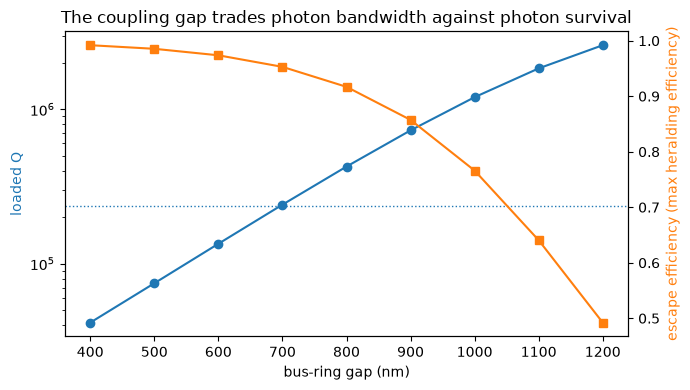

In [5]:
rows = cp["q_vs_gap"]
gaps = [r["gap_m"] * 1e9 for r in rows]
fig, ax1 = plt.subplots(figsize=(7, 4))
ax1.semilogy(gaps, [r["QL"] for r in rows], "o-", color="tab:blue", label="loaded Q")
ax1.axhline(235e3, color="tab:blue", ls=":", lw=1)
ax1.set_xlabel("bus-ring gap (nm)"); ax1.set_ylabel("loaded Q", color="tab:blue")
ax2 = ax1.twinx()
ax2.plot(gaps, [r["eta_esc"] for r in rows], "s-", color="tab:orange", label="escape efficiency")
ax2.set_ylabel("escape efficiency (max heralding efficiency)", color="tab:orange")
ax1.set_title("The coupling gap trades photon bandwidth against photon survival")
fig.tight_layout(); plt.show()

**Robustness:** an EME simulation of the real curved coupler gives 0.65–0.9× the coupling of the straight-coupler model (EME not converged in span), so the gap that reaches Q_L = 235,000 lies between about 630 and 700 nm. The escape efficiency at that target does **not** depend on this: $\eta_{\text{esc}} = 1 - Q_L/Q_i$ only involves the target Q_L and the loss. The coupling model moves the gap, not the quantum performance.

## 3. Dispersion → resonance alignment → usable frequency bins

A photon pair born from the pump must satisfy energy conservation and land on resonances. Dispersion moves the resonances out of line by

$$\Delta_k = \omega_{p+k} + \omega_{p-k} - 2\omega_p \approx D_2 k^2,\qquad D_2 = \frac{\lambda^2 D\,(2\pi\,\mathrm{FSR})^2}{2\pi n_g}$$

and a pair in bin $k$ is suppressed by the Lorentzian overlap $1/(1 + (2\Delta_k/\Gamma)^2)$. The simulation computed $\Delta_k$ from the exact resonance condition $n_{\text{eff}}(\lambda)L = m\lambda$; here it is compared with the analytic $D_2 k^2$. The Hydex core dispersion is unknown, so D is scaled from 0.5× to 10×.

PASS  D2 by hand vs simulation (relative): simulation = 1.0000, theory = 1.0000
PASS  Delta_10 exact vs D2 k^2 (relative): simulation = 0.9995, theory = 1.0000
PASS  brightness formula at k = 10: simulation = 0.7418, theory = 0.7418


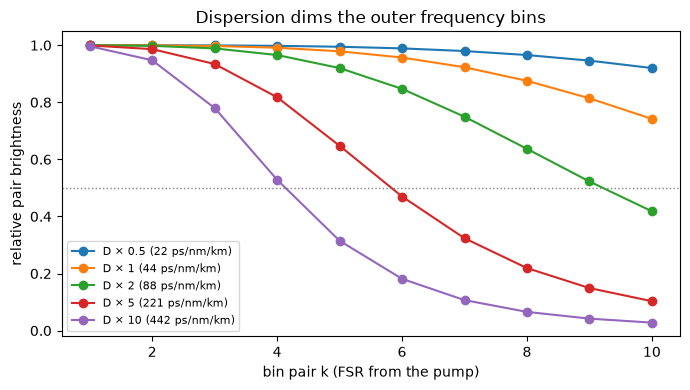

In [6]:
pump = ds["pump"]
LW = ds["inputs"]["linewidth_Hz"]
base = ds["bins_vs_D_scale"]["1"]
D2 = pump["lam_m"] ** 2 * base["D_ps_nm_km"] * 1e-6 * (2 * np.pi * pump["FSR_Hz"]) ** 2 / (2 * np.pi * pump["ng"])
check("D2 by hand vs simulation (relative)", D2 / base["D2_rad_s"], 1.0, tol=0.01)
k10 = base["bins"][-1]
check("Delta_10 exact vs D2 k^2 (relative)", k10["Delta_numeric_Hz"] / (D2 * 100 / (2 * np.pi)), 1.0, tol=0.01)
check("brightness formula at k = 10", 1 / (1 + (2 * k10["Delta_numeric_Hz"] / LW) ** 2), k10["brightness_numeric"], tol=1e-6)

plt.figure(figsize=(7, 4))
for s, entry in ds["bins_vs_D_scale"].items():
    ks = [b["k"] for b in entry["bins"]]
    plt.plot(ks, [b["brightness_numeric"] for b in entry["bins"]], "o-", label=f"D × {s} ({entry['D_ps_nm_km']:.0f} ps/nm/km)")
plt.axhline(0.5, color="gray", ls=":", lw=1)
plt.xlabel("bin pair k (FSR from the pump)"); plt.ylabel("relative pair brightness")
plt.title("Dispersion dims the outer frequency bins")
plt.legend(fontsize=8); plt.tight_layout(); plt.show()

With the modelled dispersion, bin 10 keeps 74 % of the brightness of bin 1. The measured joint spectrum of the real chip shows all 10 bin pairs within about 2× of each other, which is consistent with D up to about 2× the model and rules out D ≥ 5×: the measurement constrains the unknown core dispersion.

**Avoided crossings** with higher-order mode families could dim individual bins. Two such families can couple to TE0 and drift about 2 GHz per bin relative to it, but the model's precision (~7 GHz from mesh, ~1.1 GHz per 1e-5 in n_eff) is coarser than the 0.8 GHz linewidth, so their positions cannot be predicted; a measured transmission spectrum would show them.

## 4. Quantum consequences

**Bin imbalance and entanglement.** The frequency-bin state uses amplitudes $c_k \propto \sqrt{\text{brightness}_k}$ for the $D$ bin pairs nearest the pump (assumed). Its fidelity to the maximally entangled state is computed in QuTiP and compared with $(\sum_k \sqrt{p_k})^2/D$.

In [7]:
bright = [b["brightness_numeric"] for b in base["bins"]]
def F_imbalance(D):
    p = np.array(bright[:D]) / sum(bright[:D])
    psi = sum(np.sqrt(p[k]) * qt.tensor(qt.basis(D, k), qt.basis(D, k)) for k in range(D))
    Phi = sum(qt.tensor(qt.basis(D, k), qt.basis(D, k)) for k in range(D)).unit()
    return abs(Phi.dag() * psi) ** 2, np.sum(np.sqrt(p)) ** 2 / D

F_meas = {2: 0.885, 3: 0.809, 4: 0.766}
for D in [2, 3, 4]:
    Fq, Fa = F_imbalance(D)
    check(f"D = {D}: QuTiP fidelity vs analytic", Fq, Fa, tol=1e-9)
    print(f"   imbalance infidelity {1 - Fq:.1e}  vs measured infidelity {1 - F_meas[D]:.3f}")

PASS  D = 2: QuTiP fidelity vs analytic: simulation = 1.0000, theory = 1.0000
   imbalance infidelity 1.7e-08  vs measured infidelity 0.115
PASS  D = 3: QuTiP fidelity vs analytic: simulation = 1.0000, theory = 1.0000
   imbalance infidelity 3.6e-07  vs measured infidelity 0.191
PASS  D = 4: QuTiP fidelity vs analytic: simulation = 1.0000, theory = 1.0000
   imbalance infidelity 3.1e-06  vs measured infidelity 0.234


Bin imbalance explains about 0.001 % of the measured loss of fidelity (notebook 12): the chip is not the cause.

**Coherence time.** The paper quotes ~0.6 ns for a ~800 MHz linewidth but gives no formula. Common conventions differ by factors of 2 and π:

In [8]:
G = ch["linewidth_Hz"]
for label, val in [("1/Γ", 1 / G), ("1/(πΓ)", 1 / (np.pi * G)), ("1/(2πΓ)", 1 / (2 * np.pi * G)), ("1/(2Γ)", 1 / (2 * G))]:
    print(f"{label:>9}: {val * 1e9:.2f} ns")
check("1/(2 linewidth) vs paper ~0.6 ns", 1 / (2 * G) * 1e9, 0.6, tol=0.02)

      1/Γ: 1.22 ns
   1/(πΓ): 0.39 ns
  1/(2πΓ): 0.19 ns
   1/(2Γ): 0.61 ns
PASS  1/(2 linewidth) vs paper ~0.6 ns: simulation = 0.6075, theory = 0.6000


## Summary: design choice → quantum figure of merit

| Design quantity | Value | Quantum consequence |
|---|---|---|
| Waveguide 1.50 × 1.45 µm, n = 1.70 | n_g = 1.745, R = 136.9 µm | 200 GHz frequency-bin spacing |
| Coupling gap ≈ 0.70 µm (0.63–0.70 with EME) | Q_L = 235,000, linewidth 823 MHz | photon coherence time ~0.6 ns (1/2Γ) |
| Q_L / Q_i = 0.046 | η_esc = 0.954 | heralding efficiency ≤ 95 % |
| D = 44 ps/(nm·km) | bin 10 at 74 % brightness | ≥ 10 usable bin pairs; bin imbalance negligible for D ≤ 4 |

**Open items:** EME span convergence of the coupler; positions of avoided crossings; the core material's dispersion; bend loss (needs absorbing boundaries).

## Validation summary

Every `check` above compared a QuTiP result with its analytic formula.

In [9]:
print(f"{sum(results)} of {len(results)} checks passed")
assert all(results), "a simulation disagrees with theory"

15 of 15 checks passed
